In [12]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from astropy.io import fits
from pprint import pprint

from talltable import PixelQuery

In [114]:
with fits.open('../data/LRG_NGC_clustering.dat.fits') as hdul:
    data = hdul[1].data
    pprint(hdul[1].header)

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   97 / length of dimension 1                          
NAXIS2  =              1476135 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   13 / number of table fields                         
TTYPE1  = 'TARGETID'                                                            
TFORM1  = 'K       '                                                            
TTYPE2  = 'Z       '                                                            
TFORM2  = 'D       '                                                            
TTYPE3  = 'NTILE   '        

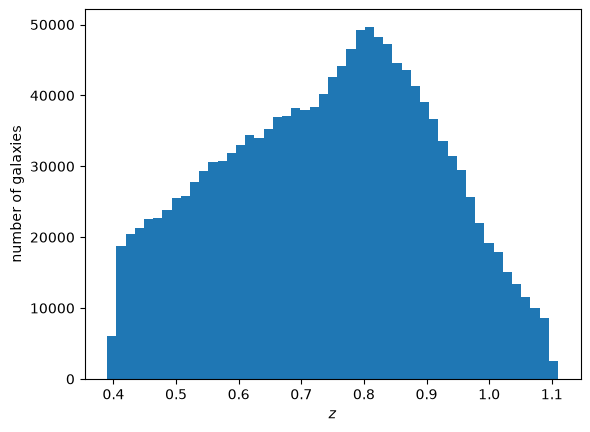

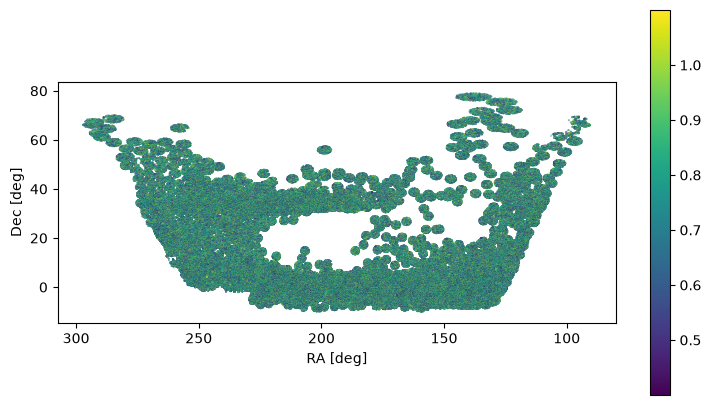

In [53]:
plt.hist(data['Z'], bins=np.linspace(0.39, 1.11, 50))
plt.xlabel('$z$')
plt.ylabel('number of galaxies')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(data['RA'], data['DEC'], c=data['Z'], marker='.', s=0.1)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

In [56]:
mask = (data['Z'] > 0.5) & (data['Z'] < 0.51)
print(np.count_nonzero(mask))

sample = data[mask]

17706


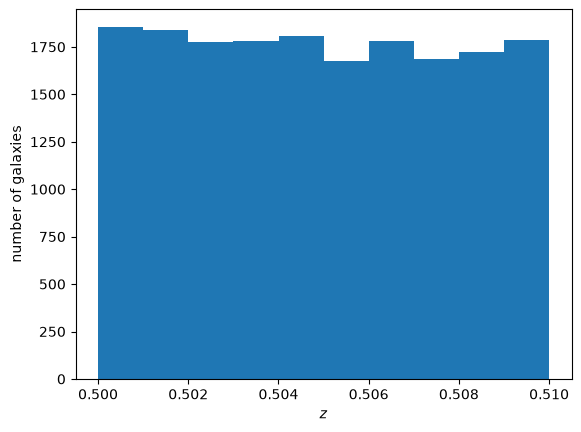

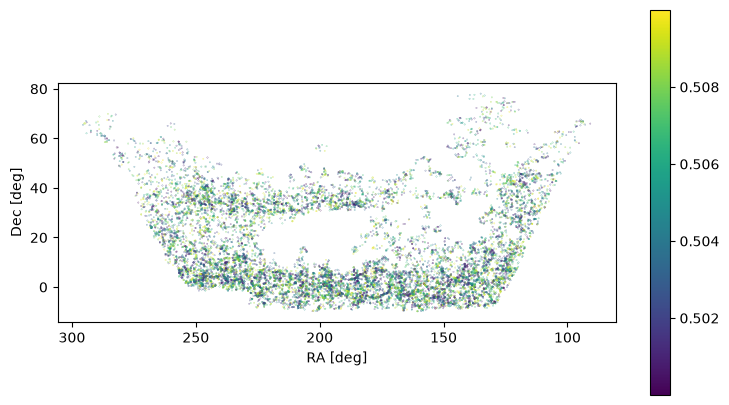

In [60]:
plt.hist(sample['Z'])
plt.xlabel('$z$')
plt.ylabel('number of galaxies')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(sample['RA'], sample['DEC'], c=sample['Z'], marker='.', s=0.1)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

In [61]:
import healpy

In [65]:
hp15 = healpy.ang2pix(2**15, sample['RA'], sample['DEC'], nest=True, lonlat=True)
sort_idx = np.argsort(hp15)

sample = sample[sort_idx]
hp15 = hp15[sort_idx]

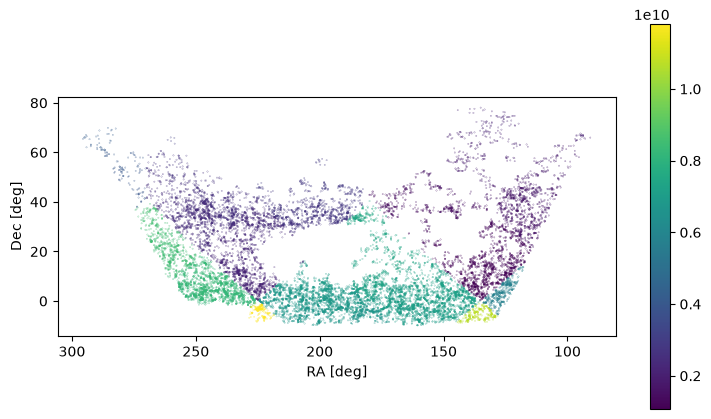

In [66]:
fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(sample['RA'], sample['DEC'], c=hp15, marker='.', s=0.1)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

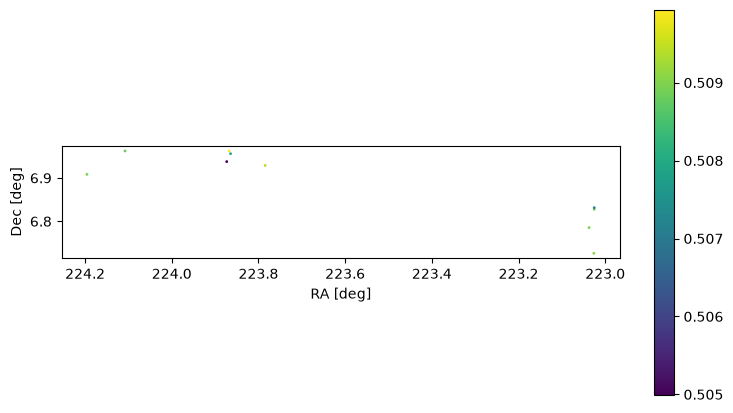

In [81]:
rng = np.random.default_rng(112)
chosen = rng.choice(len(hp15), size=1).item()

tiny_mask = np.zeros_like(hp15, dtype=bool)
tiny_mask[ chosen-5:chosen+5 ] = True
tiny_sample = sample[tiny_mask]

fig, ax = plt.subplots(figsize=(9, 5))
_s = ax.scatter(tiny_sample['RA'], tiny_sample['DEC'], c=tiny_sample['Z'], marker='o', s=1)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
fig.colorbar(_s)
plt.show()

In [85]:
from astropy.cosmology import Planck18
from astropy import units as units

In [96]:
f'{np.degrees(((1 * units.Mpc) / Planck18.comoving_distance(0.5)).value) * 60} arcmin'

'1.766192658521401 arcmin'

In [107]:
# import numpy as np
# import healpy as hp
# from talltable import PixelQuery
# from talltable.query import choose_filter_level, indices_to_hphigh_ranges

# RADIUS_ARCMIN = 3.0  # ~1 Mpc at z=0.5; use ~5.5 arcmin for 2 Mpc
# radius_deg = RADIUS_ARCMIN / 60.0

# # pick one HEALPix level for all discs (they're all the same size), targeting
# # ~100 pixels per disc rather than the library default of ~1000
# area_deg2 = np.pi * radius_deg**2
# level = choose_filter_level(area_deg2, target_pixels=100)
# nside = 2 ** level

# all_ipix = []
# for ra, dec in zip(tiny_sample['RA'], tiny_sample['DEC']):
#     vec = hp.ang2vec(ra, dec, lonlat=True)
#     ipix = hp.query_disc(nside, vec, np.radians(radius_deg), nest=True, inclusive=True)
#     # print(len(indices_to_hphigh_ranges(ipix, level)))
#     all_ipix.append(ipix)
# all_ipix = np.concatenate(all_ipix)
# print(len(indices_to_hphigh_ranges(all_ipix, level)))

# # PixelQuery.ipix() already unions/merges over the full index list internally
# # (indices_to_hphigh_ranges + find_partitions_ipix both dedupe across the set),
# # so feeding it one concatenated array gives us the disc union for free.
# pq = PixelQuery(web=True).ipix(all_ipix.tolist(), level).with_wavelengths()

# # print(pq.sql())
# table = pq.execute()

In [117]:
from tqdm.auto import tqdm

spherex_data = dict()

for row in tqdm(tiny_sample):
    query = PixelQuery(web=True).disc(row['RA'], row['DEC'], 3.0).with_wavelengths()
    spherex_data[row['TARGETID']] = query.execute()
    print(f"{row['TARGETID']}: found {len(spherex_data[row['TARGETID']])} rows")

  0%|          | 0/10 [00:00<?, ?it/s]

39627957286733038: found 897299 rows


39627957282541922: found 903165 rows


39627957290928767: found 697002 rows


39627957290927181: found 704954 rows


39627957286732874: found 896097 rows


39627957286732929: found 895592 rows


39627951272100653: found 893640 rows


39627951272100908: found 885625 rows


HTTPError: 504 Server Error: Gateway Time-out for url: https://talltable.flatironinstitute.org/sql

In [121]:
parts = set()
for row in tqdm(tiny_sample):
    query = PixelQuery(web=True).disc(row['RA'], row['DEC'], 3.0).with_wavelengths()
    for p in query.partitions():
        parts.add(p)

  0%|          | 0/10 [00:00<?, ?it/s]